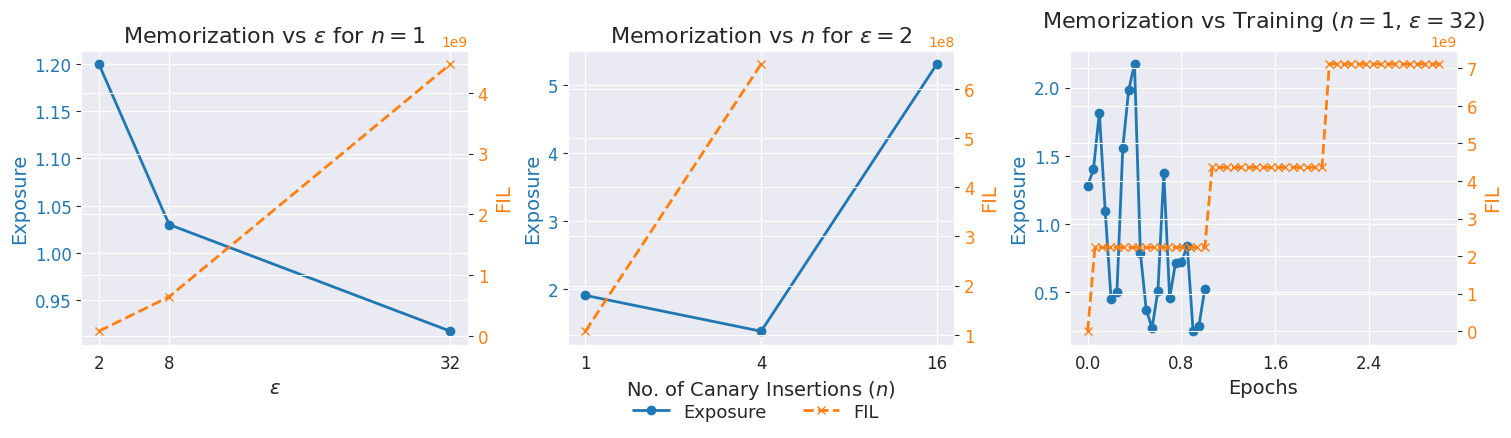

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

exp_df = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-03_Exp_Qwen.csv')
fil_df = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-03_FIL_Qwen.csv')

# ── Column helpers ────────────────────────────────────────────────────────────
def exp_col(num, eps):
    return f'Num={num},epsilon={eps}_lr=0.0001 - Exposure'

def fil_col(num, eps):
    return f'FIL Num={num},epsilon={eps} - FIL'

def get_fil_final(num, eps):
    col = fil_col(num, eps)
    return fil_df[col].iloc[-1] if col in fil_df.columns else None

def get_fil_series(num, eps):
    col = fil_col(num, eps)
    return fil_df[col] if col in fil_df.columns else None

ycols    = [col for col in exp_df.columns if col.endswith('Exposure')]
combos   = [(int(re.search(r'Num=(\d+)', c).group(1)),
             int(re.search(r'epsilon=(\d+)', c).group(1))) for c in ycols]
epsilons = sorted(set(e for _, e in combos))   # [2, 8, 32]
nums     = sorted(set(n for n, _ in combos))   # [1, 4, 16]

BLUE   = 'C0'
ORANGE = 'C1'

def add_twin_fil(ax, x, y):
    ax2 = ax.twinx()
    ax2.plot(x, y, color=ORANGE, linestyle='--', marker='x', linewidth=2)
    ax2.set_ylabel('FIL', color=ORANGE, fontsize=14)
    ax2.tick_params(axis='y', labelcolor=ORANGE, labelsize=12)
    ax2.yaxis.offsetText.set_fontsize(10)
    return ax2

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

ax1 = axs[0]
n_fixed = 1
exp_vals_eps = [exp_df[exp_col(n_fixed, e)].mean() for e in epsilons]
fil_vals_eps = [fil_df[fil_col(n_fixed, e)].mean() for e in epsilons]

# filter out any None (shouldn't happen for n=1, but safe)
fil_eps_pairs = [(e, v) for e, v in zip(epsilons, fil_vals_eps) if v is not None]
fil_eps_x, fil_eps_y = zip(*fil_eps_pairs) if fil_eps_pairs else ([], [])

ax1.plot(epsilons, exp_vals_eps, color=BLUE, marker='o')
ax1.set_xlabel(r'$\varepsilon$', fontsize=14)
ax1.set_ylabel('Exposure', color=BLUE, fontsize=14)
ax1.tick_params(axis='y', labelcolor=BLUE)
ax1.set_title(r'Memorization vs $\varepsilon$ for $n = 1$', fontsize=16)
ax1.set_xticks(epsilons)

ax1b = add_twin_fil(ax1, list(fil_eps_x), list(fil_eps_y))
ax1b.set_xticks(epsilons)

ax2 = axs[1]
eps_fixed = 2

positions = list(range(len(nums)))
labels    = [str(n) for n in nums]

exp_vals_n = [exp_df[exp_col(n, eps_fixed)].iloc[-1] for n in nums]

fil_n_x, fil_n_y = [], []
for i, n in enumerate(nums):
    v = get_fil_final(n, eps_fixed)
    if v is not None:
        fil_n_x.append(i)
        fil_n_y.append(v)

ax2.plot(positions, exp_vals_n, color=BLUE, marker='o')
ax2.set_xlabel('No. of Canary Insertions ($n$)', fontsize=14)
ax2.set_ylabel('Exposure', color=BLUE, fontsize=14)
ax2.tick_params(axis='y', labelcolor=BLUE)
ax2.set_title(r'Memorization vs $n$ for $\varepsilon = 2$', fontsize=16)
ax2.set_xticks(positions)
ax2.set_xticklabels(labels)

ax2b = add_twin_fil(ax2, fil_n_x, fil_n_y)
ax2b.set_xticks(positions)

ax3 = axs[2]
n_train, eps_train = 1, 32

exp_series = exp_df[exp_col(n_train, eps_train)]
fil_series = get_fil_series(n_train, eps_train)

x_exp = exp_df['Step']/160 if 'Step' in exp_df.columns else exp_df.index
x_fil = fil_df['Step']*3/48 if 'Step' in fil_df.columns else fil_df.index

ax3.plot(x_exp, exp_series, color=BLUE, marker='o')
ax3.set_xlabel('Epochs', fontsize=14)
ax3.set_ylabel('Exposure', color=BLUE, fontsize=14)
ax3.tick_params(axis='y', labelcolor=BLUE)
ax3.set_title(r'Memorization vs Training ($n = 1$, $\varepsilon = 32$)', fontsize=16)
ax3.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))

if fil_series is not None:
    ax3b = add_twin_fil(ax3, x_fil, fil_series)

legend_handles = [
    Line2D([0], [0], color=BLUE,   marker='o', linewidth=2, label='Exposure'),
    Line2D([0], [0], color=ORANGE, marker='x', linewidth=2, linestyle='--', label='FIL'),
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=2, fontsize=13, frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.savefig('/home/ishitak/ssh/post-review/plots_saved/run-03_Qwen.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()

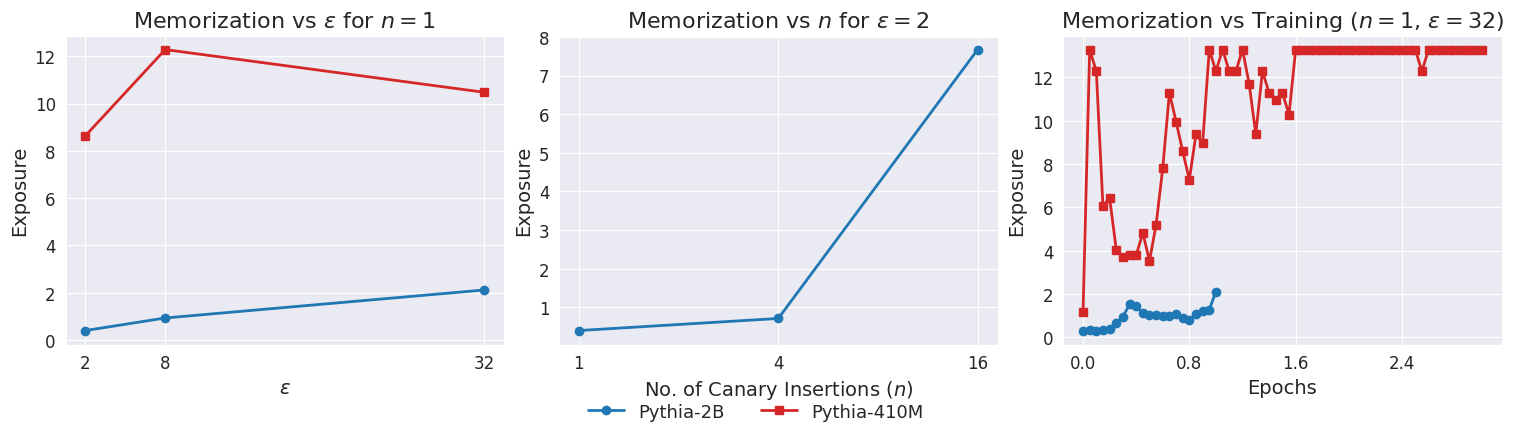

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

exp_df        = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-04_Exp_Pythia2b.csv')
df_410m       = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1.csv')
df_410m_train = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1,e=32.csv')

col_410m_train = [c for c in df_410m_train.columns if c.endswith('Exposure')][0]

def exp_col(num, eps):
    return f'Num={num},epsilon={eps}_lr=5e-05 - Exposure'

def exp_col_410m(num, eps):
    return f'Num={num},epsilon={eps} - Exposure'

ycols    = [col for col in exp_df.columns if col.endswith('Exposure')]
combos   = [(int(re.search(r'Num=(\d+)', c).group(1)),
             int(re.search(r'epsilon=(\d+)', c).group(1))) for c in ycols]
epsilons = sorted(set(e for _, e in combos))
nums     = sorted(set(n for n, _ in combos))

epsilons_410m = sorted(set(int(re.search(r'epsilon=(\d+)', c).group(1))
                           for c in df_410m.columns if c.endswith('Exposure')))

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)


ax1 = axs[0]
n_fixed = 1

exp_vals_eps_2b   = [exp_df[exp_col(n_fixed, e)].iloc[-1] for e in epsilons]
exp_vals_eps_410m = [df_410m[exp_col_410m(n_fixed, e)].iloc[-1] for e in epsilons_410m]

ax1.plot(epsilons,      exp_vals_eps_2b,   color='C0', marker='o')
ax1.plot(epsilons_410m, exp_vals_eps_410m, color='C3', marker='s')
ax1.set_xlabel(r'$\varepsilon$', fontsize=14)
ax1.set_ylabel('Exposure', fontsize=14)
ax1.set_title(r'Memorization vs $\varepsilon$ for $n = 1$', fontsize=16)
ax1.set_xticks(epsilons)

ax2 = axs[1]
eps_fixed = 2

positions  = list(range(len(nums)))
labels     = [str(n) for n in nums]
exp_vals_n = [exp_df[exp_col(n, eps_fixed)].iloc[-1] for n in nums]

ax2.plot(positions, exp_vals_n, color='C0', marker='o')
ax2.set_xlabel('No. of Canary Insertions ($n$)', fontsize=14)
ax2.set_ylabel('Exposure', fontsize=14)
ax2.set_title(r'Memorization vs $n$ for $\varepsilon = 2$', fontsize=16)
ax2.set_xticks(positions)
ax2.set_xticklabels(labels)

ax3 = axs[2]
n_train, eps_train = 1, 32

exp_series = exp_df[exp_col(n_train, eps_train)]
x_exp      = exp_df['Step'] / 160 if 'Step' in exp_df.columns else exp_df.index

x_410m     = df_410m_train['Step'] / 160 if 'Step' in df_410m_train.columns else df_410m_train.index

ax3.plot(x_exp,   exp_series,                        color='C0', marker='o')
ax3.plot(x_410m,  df_410m_train[col_410m_train],     color='C3', marker='s')
ax3.set_xlabel('Epochs', fontsize=14)
ax3.set_ylabel('Exposure', fontsize=14)
ax3.set_title(r'Memorization vs Training ($n = 1$, $\varepsilon = 32$)', fontsize=16)
ax3.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))

legend_handles = [
    Line2D([0], [0], color='C0', marker='o', linewidth=2, label='Pythia-2B'),
    Line2D([0], [0], color='C3', marker='s', linewidth=2, label='Pythia-410M'),
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=2, fontsize=13, frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.savefig('/home/ishitak/ssh/post-review/plots_saved/run-04_pythia2b.pdf',
            format='pdf', bbox_inches='tight', dpi=300)
plt.show()

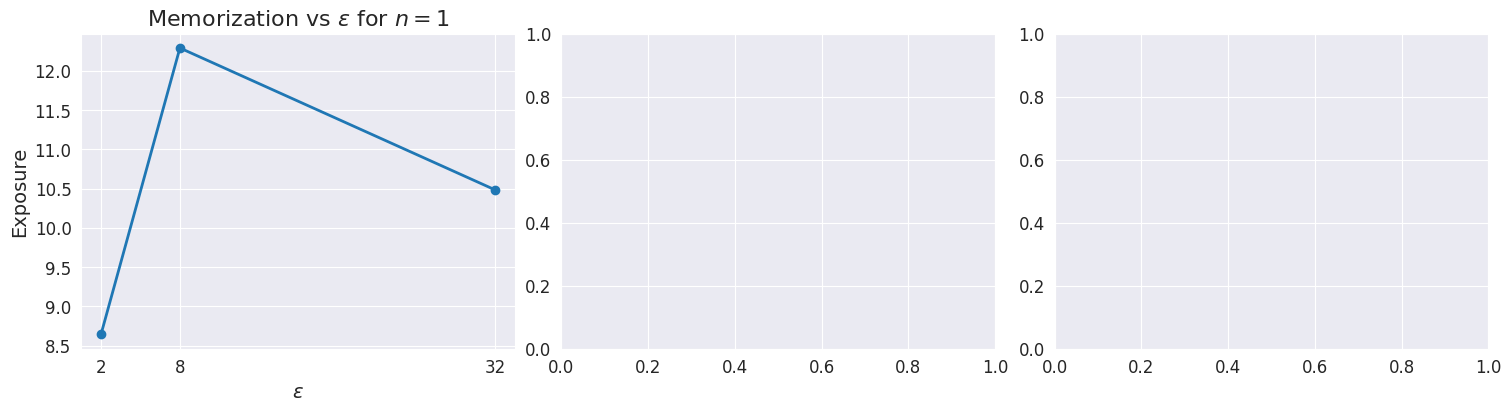

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import re
from matplotlib.lines import Line2D

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

exp_df = pd.read_csv('/home/ishitak/ssh/post-review/csvs/run-02_Exp_Pythia410m_n=1.csv')

def exp_col(num, eps):
    return f'Num={num},epsilon={eps} - Exposure'  # adjust if needed

ycols    = [col for col in exp_df.columns if col.endswith('Exposure')]
combos   = [(int(re.search(r'Num=(\d+)', c).group(1)),
             int(re.search(r'epsilon=(\d+)', c).group(1))) for c in ycols]
epsilons = sorted(set(e for _, e in combos))
nums     = sorted(set(n for n, _ in combos))

BLUE = 'C0'

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

ax1 = axs[0]
n_fixed = 1

exp_vals_eps = [exp_df[exp_col(n_fixed, e)].iloc[-1] for e in epsilons]

ax1.plot(epsilons, exp_vals_eps, color=BLUE, marker='o')
ax1.set_xlabel(r'$\varepsilon$', fontsize=14)
ax1.set_ylabel('Exposure', fontsize=14)
ax1.set_title(r'Memorization vs $\varepsilon$ for $n = 1$', fontsize=16)
ax1.set_xticks(epsilons)

plt.savefig('/home/ishitak/ssh/post-review/plots_saved/run-04_pythia2b.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()